# Compare to competition assays

In [2]:
import numpy as np 
import pandas as pd 

import matplotlib.pyplot as plt 
import matplotlib.colors as mcolors
import colorsys
import matplotlib.gridspec as gridspec
import seaborn as sns

from scipy import stats

In [5]:
data_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/data"
out_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/out"
fig_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/figures"

## Time series of estimates

Since MPL takes 1 generation = 1 day, and the assay fitness estimates used 1 generation = 1.2 days, we need to multiply them by 1.2

In [6]:
#Load data from assays
assay_fitness_estimates = np.load(data_path + "/assay_fitness_estimates.npz")
assay_means = assay_fitness_estimates['means']*1.2
assay_stds = assay_fitness_estimates['stds']*1.2

#MPL mean and std estimates
data = pd.read_pickle(out_path + "/mutation_time_series_with_fitness.pkl")
estimated_covariances = np.load(out_path + "/estimated_covariances.npz")
gamma = 5

MPL_fitness_estimates = np.zeros((4,52))
MPL_fitness_estimates_no_linkage = np.zeros((4,52))
MPL_std = np.zeros((4,52))
MPL_std_no_linkage = np.zeros((4,52))

for i, line in enumerate([13,14,15,16]):
    data_line = data[data['line']==line]
    cov_x = estimated_covariances[f'line{line}']
    cov_s = (np.linalg.inv(cov_x + gamma*np.identity(cov_x.shape[0])))/data_line['Mean pop size'].mean()

    
    for j, gen in enumerate(np.arange(0,511,10)):
        MPL_fitness_estimates[i,j] = np.sum(data_line['s']*data_line[gen])
        MPL_fitness_estimates_no_linkage[i,j] = np.sum(data_line['s no linkage']*data_line[gen])

        MPL_std[i,j] = np.sqrt(data_line[gen].values.dot(cov_s).dot(data_line[gen].values))
        MPL_std_no_linkage[i,j] = (data_line[gen].multiply(data_line['std no linkage'], axis=0)).sum(axis=0)


In [4]:
#Randomisation tests: shuffle s and calculate population fitness
num_random = 100

MPL_fitness_estimates_shuffled = np.zeros((4,52,num_random))
MPL_std_shuffled = np.zeros((4,52,num_random))

for i, line in enumerate([13,14,15,16]):
    data_line = data[data['line']==line]

    for k in range(num_random):
        shuffled_s = data_line['s'].sample(frac=1, random_state=k).values

        for j, gen in enumerate(np.arange(0,511,10)):
            MPL_fitness_estimates_shuffled[i,j,k] = np.sum(shuffled_s*data_line[gen])


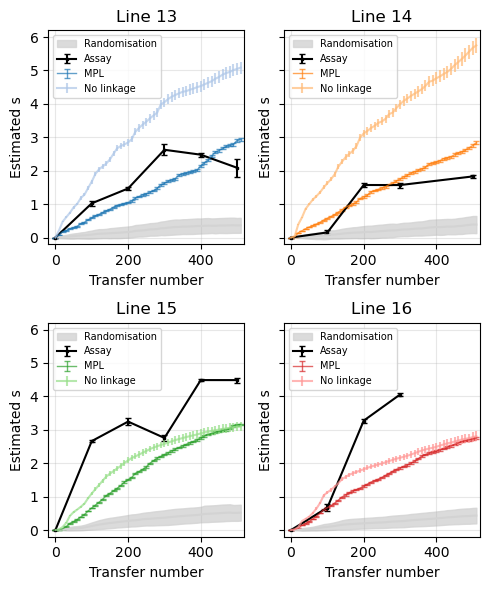

In [5]:
#Plot results
fig, axes = plt.subplots(2,2,figsize=(5,6),sharey=True)
axes = axes.flatten()
cmap = plt.get_cmap('tab20')
colours = [cmap(i)[:3] for i in range(20)]

for i, ax in enumerate(axes):
    assay_means_plot = np.concat(([0],assay_means[i,:]))
    assay_stds_plot = np.concat(([0],assay_stds[i,:]))

    mask = ~np.isnan(assay_means_plot)
    ax.errorbar(np.array([0,100,200,300,400,500])[mask],assay_means_plot[mask],yerr=assay_stds_plot[mask],marker='s',markersize=2,capsize=2,color='black',label='Assay')
    ax.errorbar(np.array(np.arange(0,511,10)),MPL_fitness_estimates[i,:],yerr=MPL_std[i,:],marker='',capsize=2, markersize=0, linewidth=1,color=colours[2*i],alpha=0.7,label='MPL')
    ax.errorbar(np.array(np.arange(0,511,10)),MPL_fitness_estimates_no_linkage[i,:],yerr=MPL_std_no_linkage[i,:],marker='',capsize=0, markersize=2,color=colours[1+2*i],alpha=0.7,label='No linkage')
    
    
    #Randomisation
    mean = MPL_fitness_estimates_shuffled[i,:,:].mean(axis=1)
    std = MPL_fitness_estimates_shuffled[i,:,:].std(axis=1)
    ax.plot(np.array(np.arange(0,511,10)),mean,color='lightgrey')
    ax.fill_between(np.array(np.arange(0,511,10)),mean-std,mean+std,color='lightgrey',alpha=0.8,label='Randomisation')

    #Format
    ax.set_xlim(-20,520)
    ax.set_ylim(-0.2,6.2)
    ax.grid(alpha=0.3)
    ax.set_ylabel('Estimated s')
    ax.set_xlabel('Transfer number')
    ax.set_title(f'Line {i+13}')
    ax.legend(loc='upper left',fontsize=7)

plt.tight_layout()
plt.savefig(fig_path + f"/assays_time_series.pdf")
plt.show()

## Scatter plots

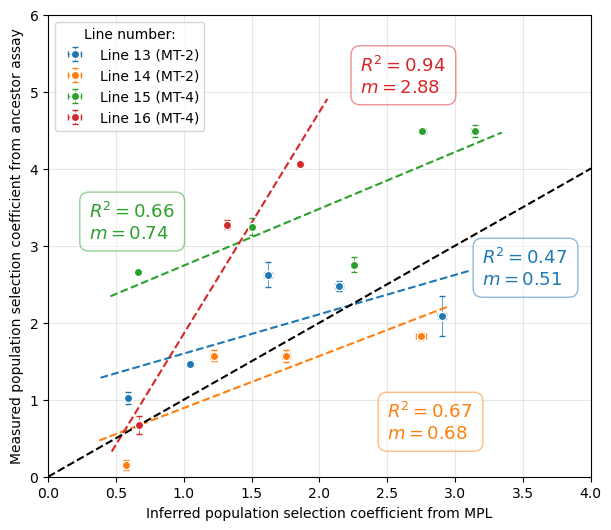

In [ ]:
#Plot scatter of all inferred vs. scattered
fig, ax = plt.subplots(1,1,figsize=(7,6))
colours = ['tab:blue','tab:orange','tab:green','tab:red']

x_ = [3.2,2.5,0.3,2.3]
y_ = [2.5,0.5,3.1,5]

for i in range(4):
    mask = ~np.isnan(assay_means[i,:])
    ax.errorbar(x=MPL_fitness_estimates[i,10::10], y=assay_means[i,:], capsize=2, elinewidth=0.5, xerr=MPL_std[i,10::10], yerr=assay_stds[i,:], fmt='o', markersize=6, linestyle='None', markeredgecolor='white', color=colours[i],label=f'Line {i+13} (MT-{(np.floor(i/2)*2 +2).astype(int)})')
    
    m, c, r, p, std_err = stats.linregress(MPL_fitness_estimates[i,10::10][mask], assay_means[i,:][mask])
    x = np.linspace(MPL_fitness_estimates[i,10::10][mask].min()-0.2,MPL_fitness_estimates[i,10::10][mask].max()+0.2,10) 
    y = m*x + c
    ax.plot(x,y,'--',color=colours[i])
    
    ax.text(x_[i],y_[i],f'$R^2=${r**2:.2f} \n$m=${m:.2f}',color=colours[i],size=13,bbox=dict(facecolor='white', alpha=0.5, edgecolor=colours[i], boxstyle='round,pad=0.5'))

ax.plot(np.linspace(0,5,5),np.linspace(0,5,5),'--',color='black')

ax.legend(title='Line number:',loc='upper left')
ax.set_ylim(0,6)
ax.set_xlim(0,4)
ax.set_xlabel('Inferred population selection coefficient from MPL')
ax.set_ylabel('Measured population selection coefficient from ancestor assay')
ax.grid(alpha=0.3)
plt.savefig(fig_path + f"/assays_scatter_MPL.pdf")
plt.show()

In [8]:
mask = ~np.isnan(assay_means.flatten())
m, c, r, p, std_err = stats.linregress(MPL_fitness_estimates[:,10::10].flatten()[mask],assay_means.flatten()[mask])
print(f'Overall r^2= {r**2:.3f}')

rmse = np.sqrt(np.mean(np.square(MPL_fitness_estimates[:,10::10].flatten()[mask]-assay_means.flatten()[mask])))
print(f'Overall RMSE= {rmse:.3f}')

Overall r^2= 0.380
Overall RMSE= 1.190


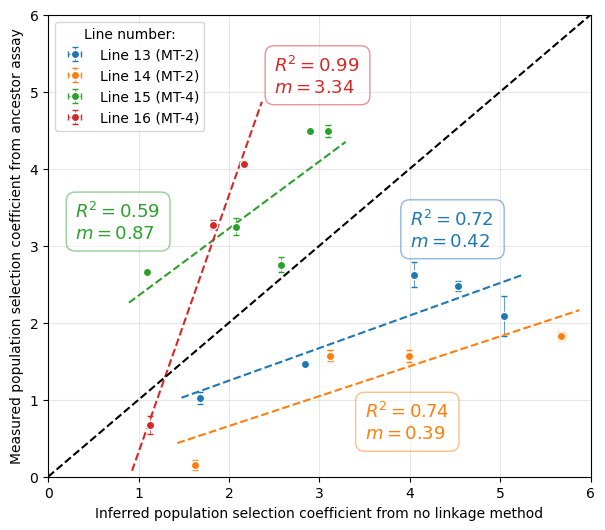

In [ ]:
#Plot scatter of all inferred vs. scattered no linkage method
fig, ax = plt.subplots(1,1,figsize=(7,6))
colours = ['tab:blue','tab:orange','tab:green','tab:red']

x_ = [4,3.5,0.3,2.5]
y_ = [3,0.5,3.1,5]

for i in range(4):
    mask = ~np.isnan(assay_means[i,:])
    ax.errorbar(x=MPL_fitness_estimates_no_linkage[i,10::10], y=assay_means[i,:], capsize=2, elinewidth=0.5, xerr=MPL_std[i,10::10], yerr=assay_stds[i,:], fmt='o', markersize=6, linestyle='None', markeredgecolor='white', color=colours[i],label=f'Line {i+13} (MT-{(np.floor(i/2)*2 +2).astype(int)})')
    
    m, c, r, p, std_err = stats.linregress(MPL_fitness_estimates_no_linkage[i,10::10][mask], assay_means[i,:][mask])
    x = np.linspace(MPL_fitness_estimates_no_linkage[i,10::10][mask].min()-0.2,MPL_fitness_estimates_no_linkage[i,10::10][mask].max()+0.2,10) 
    y = m*x + c
    ax.plot(x,y,'--',color=colours[i])
    
    ax.text(x_[i],y_[i],f'$R^2=${r**2:.2f} \n$m=${m:.2f}',color=colours[i],size=13,bbox=dict(facecolor='white', alpha=0.5, edgecolor=colours[i], boxstyle='round,pad=0.5'))

ax.plot(np.linspace(0,6,5),np.linspace(0,6,5),'--',color='black')

ax.legend(title='Line number:',loc='upper left')
ax.set_ylim(0,6)
ax.set_xlim(0,6)
ax.set_xlabel('Inferred population selection coefficient from no linkage method')
ax.set_ylabel('Measured population selection coefficient from ancestor assay')
ax.grid(alpha=0.3)
plt.savefig(fig_path + f"/assays_scatter_no_linkage.pdf")
plt.show()

In [10]:
mask = ~np.isnan(assay_means.flatten())
m, c, r, p, std_err = stats.linregress(MPL_fitness_estimates_no_linkage[:,10::10].flatten()[mask],assay_means.flatten()[mask])
print(f"Overall r^2= {r**2:.3f}")

rmse = np.sqrt(np.mean(np.square(MPL_fitness_estimates_no_linkage[:,10::10].flatten()[mask]-assay_means.flatten()[mask])))
print(f'Overall RMSE= {rmse:.3f}')

Overall r^2= 0.004
Overall RMSE= 1.827


## Figure 3

In [11]:
#Choose random genotype fitnesses
num_genotypes = 1000
genotype_fitnesses = np.zeros((4,52,num_genotypes))
for j,line in enumerate([13,14,15,16]):
    data_line = data[data['line']==line]
    for g in range(52):
        for i in range(num_genotypes):
            mask = np.random.rand(len(data_line)) < data_line[g*10]
            genotype_fitnesses[j,g,i] = np.sum(data_line.loc[mask,'s'])

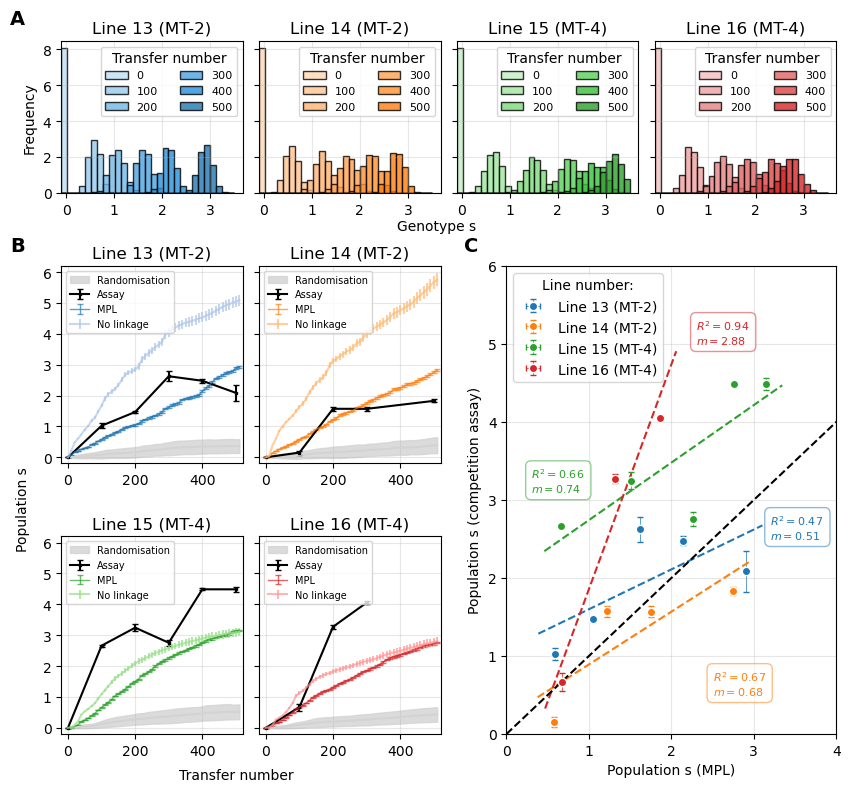

In [ ]:
fig = plt.figure(figsize=(10, 9))

#Define grid
gs = fig.add_gridspec(nrows=3,ncols=8,height_ratios=[1,1.3,1.3],width_ratios=[0.5,0.5,0.5,0.5,0.2,0.8,0.5,0.5],wspace=0.2,hspace=0.4)
ax1 = fig.add_subplot(gs[0, 0:2])
ax2 = fig.add_subplot(gs[0, 2:4]) 
ax3 = fig.add_subplot(gs[0, 4:6])
ax4 = fig.add_subplot(gs[0, 6:8])
ax5 = fig.add_subplot(gs[1, 0:2])
ax6 = fig.add_subplot(gs[1, 2:4])
ax7 = fig.add_subplot(gs[2, 0:2])
ax8 = fig.add_subplot(gs[2, 2:4])
ax9 = fig.add_subplot(gs[1:3, 5:8])
ax2.sharey(ax1)
ax3.sharey(ax1)
ax4.sharey(ax1)

#Genotype fitnesses
axes = [ax1,ax2,ax3,ax4]
for j in range(4):
    h, l, s = colorsys.rgb_to_hls(*mcolors.to_rgb(colours[j]))
    for i,g in enumerate(range(0,52,10)):
        new_l = 0.85 - i*(0.85 - l)/5
        axes[j].hist(genotype_fitnesses[j,g,:],bins=np.linspace(-0.1,3.5,30),color=colorsys.hls_to_rgb(h, new_l, s), edgecolor='black',density=True,label=str(g*10),alpha=0.8)

    #Format
    axes[j].set_xlim(left=-0.1)
    axes[j].grid(alpha=0.3)
    axes[j].legend(title='Transfer number',fontsize=8,ncols=2)
    axes[j].set_title(f'Line {j+13} (MT-{(np.floor(j/2)*2 +2).astype(int)})')

ax1.set_ylabel('Frequency')
ax2.tick_params(labelleft=False)
ax3.tick_params(labelleft=False)
ax4.tick_params(labelleft=False)
fig.text(0.5,0.67,'Genotype s',ha='center',fontsize=10)
ax1.text(-0.2, 2.3, 'A', transform=ax5.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#Time evolution
cmap = plt.get_cmap('tab20')
colours = [cmap(i)[:3] for i in range(20)]

axes = [ax5,ax6,ax7,ax8]
for i, ax in enumerate(axes):
    assay_means_plot = np.concat(([0],assay_means[i,:]))
    assay_stds_plot = np.concat(([0],assay_stds[i,:]))

    mask = ~np.isnan(assay_means_plot)
    ax.errorbar(np.array([0,100,200,300,400,500])[mask],assay_means_plot[mask],yerr=assay_stds_plot[mask],marker='s',markersize=2,capsize=2,color='black',label='Assay')
    ax.errorbar(np.array(np.arange(0,511,10)),MPL_fitness_estimates[i,:],yerr=MPL_std[i,:],marker='',capsize=2, markersize=0, linewidth=1,color=colours[2*i],alpha=0.7,label='MPL')
    ax.errorbar(np.array(np.arange(0,511,10)),MPL_fitness_estimates_no_linkage[i,:],yerr=MPL_std_no_linkage[i,:],marker='',capsize=0, markersize=2,color=colours[1+2*i],alpha=0.7,label='No linkage')
    
    #Randomisation
    mean = MPL_fitness_estimates_shuffled[i,:,:].mean(axis=1)
    std = MPL_fitness_estimates_shuffled[i,:,:].std(axis=1)
    ax.plot(np.array(np.arange(0,511,10)),mean,color='lightgrey')
    ax.fill_between(np.array(np.arange(0,511,10)),mean-std,mean+std,color='lightgrey',alpha=0.8,label='Randomisation')

    #Format
    ax.set_xlim(-20,520)
    ax.set_ylim(-0.2,6.2)
    ax.grid(alpha=0.3)
    ax.set_title(f'Line {i+13} (MT-{(np.floor(i/2)*2 +2).astype(int)})')
    ax.legend(loc='upper left',fontsize=7))
    if i==1 or i==3:
        ax.tick_params(labelleft=False)

fig.text(0.3,0.06,'Transfer number',ha='center',fontsize=10)
fig.text(0.08,0.36,'Population s',va='center',fontsize=10,rotation=90)
ax5.text(-0.2, 1.15, 'B', transform=ax5.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#Scatter plot
x_ = [3.2,2.5,0.3,2.3]
y_ = [2.5,0.5,3.1,5]
colours = ['tab:blue','tab:orange','tab:green','tab:red']

for i in range(4):
    mask = ~np.isnan(assay_means[i,:])
    ax9.errorbar(x=MPL_fitness_estimates[i,10::10], y=assay_means[i,:], capsize=2, elinewidth=0.5, xerr=MPL_std[i,10::10], yerr=assay_stds[i,:], fmt='o', markersize=6, linestyle='None', markeredgecolor='white', color=colours[i],label=f'Line {i+13} (MT-{(np.floor(i/2)*2 +2).astype(int)})')
    
    m, c, r, p, std_err = stats.linregress(MPL_fitness_estimates[i,10::10][mask], assay_means[i,:][mask])
    x = np.linspace(MPL_fitness_estimates[i,10::10][mask].min()-0.2,MPL_fitness_estimates[i,10::10][mask].max()+0.2,10) 
    y = m*x + c
    ax9.plot(x,y,'--',color=colours[i])
    
    ax9.text(x_[i],y_[i],f'$R^2=${r**2:.2f} \n$m=${m:.2f}',color=colours[i],size=8,bbox=dict(facecolor='white', alpha=0.5, edgecolor=colours[i], boxstyle='round,pad=0.5'))

ax9.plot(np.linspace(0,5,5),np.linspace(0,5,5),'--',color='black')

ax9.legend(title='Line number:',loc='upper left')
ax9.set_ylim(0,6)
ax9.set_xlim(0,4)
ax9.set_xlabel('Population s (MPL)')
ax9.set_ylabel('Population s (competition assay)')
ax9.grid(alpha=0.3)
ax9.text(2.3, 1.15, 'C', transform=ax5.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

plt.savefig(fig_path + '/Figure_3.pdf')
plt.show()

## Figure SI12

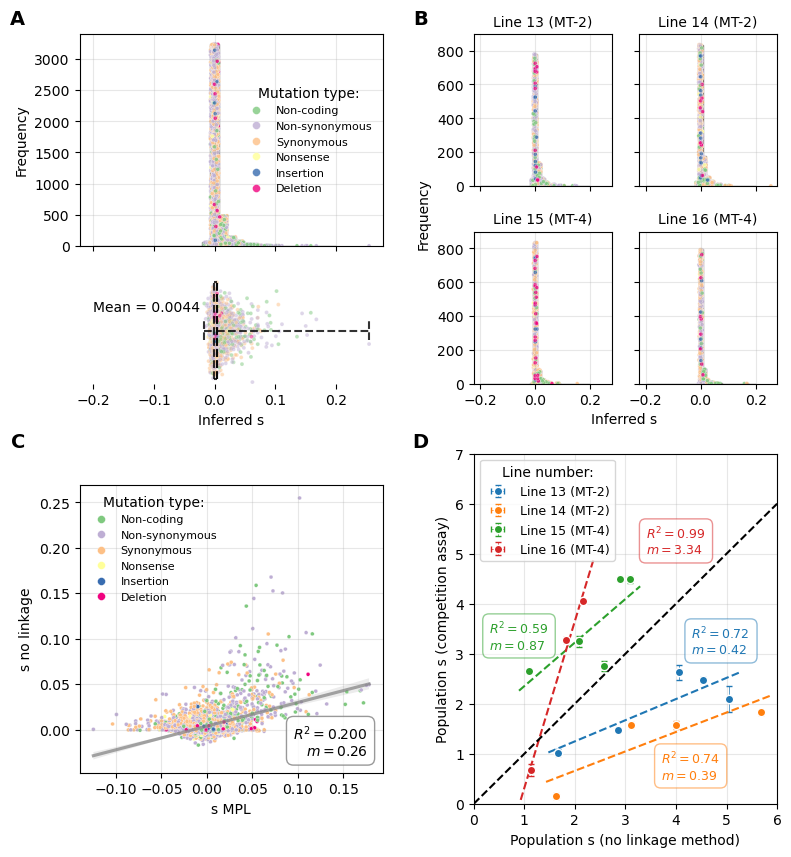

In [79]:
fig = plt.figure(figsize=(9, 10))

outer = gridspec.GridSpec(2, 2, figure=fig, wspace=0.3)
ax1 = fig.add_subplot(outer[0, 0])
ax2 = fig.add_subplot(outer[0, 1])
ax3 = fig.add_subplot(outer[1, 0])
ax4 = fig.add_subplot(outer[1, 1])

inner_1 = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[0, 0], height_ratios=[1,0.5])
ax1_1 = fig.add_subplot(inner_1[0])
ax1_2 = fig.add_subplot(inner_1[1])
ax1_2.sharex(ax1_1)
ax1.axis('off')

inner_2 = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=outer[0, 1], wspace=0.2, hspace=0.3)
ax2_1 = fig.add_subplot(inner_2[0, 0])
ax2_2 = fig.add_subplot(inner_2[0, 1])
ax2_3 = fig.add_subplot(inner_2[1, 0])
ax2_4 = fig.add_subplot(inner_2[1, 1])
ax2.axis('off')
ax2_2.sharex(ax2_1)
ax2_3.sharex(ax2_1)
ax2_4.sharex(ax2_1)

cmap = plt.colormaps['Accent']
colors = list(cmap(np.linspace(0, 0.7, 6)))

#Plot combined DFE
muts_data = data.copy()
counts = ax1_1.hist(muts_data['s no linkage'],bins=np.linspace(-0.2,0.2,30),alpha=0.5,edgecolor='black',facecolor='lightblue')
muts_data['y_jitter'] = np.zeros(len(muts_data))
for i in range(len(counts[0])):
    muts_data.loc[(muts_data['s no linkage']>counts[1][i]) & (muts_data['s no linkage']<=counts[1][i+1]),'y_jitter'] = np.random.uniform(0, counts[0][i], size=counts[0][i].astype(int))
sns.scatterplot(data=muts_data, x='s no linkage', y='y_jitter', ax=ax1_1,alpha=0.8,s=8,hue='muttype',palette=colors,edgecolor="white",legend=True)

ax1_1.grid(alpha=0.3)
ax1_1.set_ylabel('Frequency')
ax1_1.set_xlabel('')
ax1_1.legend(loc='center right', ncol=1, title='Mutation type:', frameon=False, markerscale=2,fontsize=8)
ax1_1.tick_params(axis="x", which="both", bottom=True, labelbottom=False)


#Box plot
sns.scatterplot(data=muts_data, x='s no linkage', y=np.random.normal(0.5, 0.15, size=len(muts_data)), ax=ax1_2,alpha=0.5,s=8,hue='muttype',palette=colors,edgecolor="white",legend=False)
mean = muts_data['s no linkage'].mean()      
q1 = np.percentile(muts_data['s no linkage'],25)
q2 = np.percentile(muts_data['s no linkage'],75)

ax1_2.plot(np.zeros(5)+mean,np.linspace(0,1,5),'--',color='black',alpha=0.8)
ax1_2.plot(q1+np.zeros(5),np.linspace(0,1,5),'--',color='black',alpha=0.8)
ax1_2.plot(q2+np.zeros(5),np.linspace(0,1,5),'--',color='black',alpha=0.8)
ax1_2.plot(np.linspace(q1,q2,5),np.zeros(5),'--',color='black',alpha=0.8)
ax1_2.plot(np.linspace(q1,q2,5),np.zeros(5)+1,'--',color='black',alpha=0.8)
ax1_2.plot(np.linspace(q2,muts_data['s no linkage'].max(),5),0.5+np.zeros(5),'--',color='black',alpha=0.8)
ax1_2.plot(np.linspace(muts_data['s no linkage'].min(),q1,5),0.5+np.zeros(5),'--',color='black',alpha=0.8)
ax1_2.plot(muts_data['s no linkage'].max()+np.zeros(5),np.linspace(0.4,0.6,5),'--',color='black',alpha=0.8)
ax1_2.plot(muts_data['s no linkage'].min()+np.zeros(5),np.linspace(0.4,0.6,5),'--',color='black',alpha=0.8)

ax1_2.spines[['left','right','top','bottom']].set_visible(False)
ax1_2.set_yticks(ticks=[],labels=[])
ax1_2.set_ylim(-0.05,1.05)
ax1_2.set_xlabel('Inferred s')
ax1_2.text(-0.2,0.7,f'Mean = {mean:.4f}')

ax1.text(-0.18, 1.07, 'A', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


#Individual DFEs
line_colours = ['tab:blue','tab:orange','tab:green','tab:red']

for j,ax in enumerate([ax2_1,ax2_2,ax2_3,ax2_4]):

    muts_line = data[data['line']==j+13].copy()

    counts = ax.hist(muts_line['s no linkage'],bins=np.linspace(-0.2,0.2,30),alpha=0.5,edgecolor='black',facecolor=line_colours[j])
    muts_line['y_jitter'] = np.zeros(len(muts_line))
    for i in range(len(counts[0])):
        muts_line.loc[(muts_line['s no linkage']>counts[1][i]) & (muts_line['s no linkage']<=counts[1][i+1]),'y_jitter'] = np.random.uniform(0, counts[0][i], size=counts[0][i].astype(int))
    sns.scatterplot(data=muts_line, x='s no linkage', y='y_jitter', ax=ax,alpha=0.8,s=8,hue='muttype',palette=colors,edgecolor="white",legend=False)

    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.grid(alpha=0.3)
    ax.set_title(f'Line {j+13} (MT-{(np.floor(j/2)*2 +2).astype(int)})', fontsize=10)
    ax.set_ylim(0,900) 

    if j<2:
        ax.tick_params(axis="x", which="both", bottom=True, labelbottom=False)
    if j==1 or j==3:
        ax.tick_params(axis="y", which="both", left=True, labelleft=False)

fig.text(0.73,0.49,'Inferred s',ha='center',fontsize=10)
fig.text(0.5,0.7,'Frequency',va='center',fontsize=10,rotation=90)
ax2.text(1.15, 1.07, 'B', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')



#Correlation to MPL 
sns.regplot(data=data, x='s', y='s no linkage', ax=ax3, scatter=False, line_kws={'alpha':0.7,'color':'grey'})
sns.scatterplot(data=data, x='s', y='s no linkage', ax=ax3, hue='muttype',palette=colors,edgecolor="white",s=8,legend=True)
m,_,r,_,_ = stats.linregress(data['s'], data['s no linkage'])
ax3.text(0.95,0.05,f'$R^2=${r**2:.3f}\n$m=${m:.2f}',transform=ax3.transAxes,fontsize=10,verticalalignment="bottom",horizontalalignment="right",bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8, edgecolor="gray"))

ax3.set_aspect('equal')
ax3.grid(alpha=0.3)
ax3.set_xlabel('s MPL')
ax3.legend(ncol=1, title='Mutation type:', frameon=False, markerscale=2,fontsize=8)
ax3.text(-0.18, -0.14, 'C', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


#Scatter with assay
x_ = [4.3,3.7,0.3,3.4]
y_ = [3,0.5,3.1,5]

for i in range(4):
    mask = ~np.isnan(assay_means[i,:])
    ax4.errorbar(x=MPL_fitness_estimates_no_linkage[i,10::10], y=assay_means[i,:], capsize=2, elinewidth=0.5, xerr=MPL_std[i,10::10], yerr=assay_stds[i,:], fmt='o', markersize=6, linestyle='None', markeredgecolor='white', color=line_colours[i],label=f'Line {i+13} (MT-{(np.floor(i/2)*2 +2).astype(int)})')
    
    m, c, r, p, std_err = stats.linregress(MPL_fitness_estimates_no_linkage[i,10::10][mask], assay_means[i,:][mask])
    x = np.linspace(MPL_fitness_estimates_no_linkage[i,10::10][mask].min()-0.2,MPL_fitness_estimates_no_linkage[i,10::10][mask].max()+0.2,10) 
    y = m*x + c
    ax4.plot(x,y,'--',color=colours[i])

    ax4.text(x_[i],y_[i],f'$R^2=${r**2:.2f} \n$m=${m:.2f}',color=colours[i],size=9,bbox=dict(facecolor='white', alpha=0.5, edgecolor=line_colours[i], boxstyle='round,pad=0.5'))

ax4.plot(np.linspace(0,6,5),np.linspace(0,6,5),'--',color='black')

ax4.legend(title='Line number:',loc='upper left',fontsize=9)
ax4.set_ylim(0,7)
ax4.set_xlim(0,6)
ax4.set_xlabel('Population s (no linkage method)')
ax4.set_ylabel('Population s (competition assay)')
ax4.grid(alpha=0.3)
ax4.text(1.15, -0.14, 'D', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


plt.savefig(fig_path + f"/Figure_SI12.pdf", bbox_inches='tight')
plt.show()